# Análisis exploratorio de los viajes en taxi

In [1]:
#Importar librerias y cargar archivos
import pandas as pd
import numpy as np
import seaborn as sns
from matplotlib import pyplot as plt
from scipy import stats as st

#Cargar archivos
df_trips = pd.read_csv('/datasets/project_sql_result_01.csv')
df_dropoff = pd.read_csv('/datasets/project_sql_result_04.csv')


In [2]:
#Análisis general de los datos en ambos Dataframes
print(df_trips.info())
print(df_trips.head(10))
print()
print(df_trips.duplicated().sum())
print()

print(df_dropoff.info())
print(df_dropoff.head(10))
print()
print(df_dropoff.duplicated().sum())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 64 entries, 0 to 63
Data columns (total 2 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   company_name  64 non-null     object
 1   trips_amount  64 non-null     int64 
dtypes: int64(1), object(1)
memory usage: 1.1+ KB
None
                        company_name  trips_amount
0                          Flash Cab         19558
1          Taxi Affiliation Services         11422
2                  Medallion Leasing         10367
3                         Yellow Cab          9888
4    Taxi Affiliation Service Yellow          9299
5          Chicago Carriage Cab Corp          9181
6                       City Service          8448
7                           Sun Taxi          7701
8          Star North Management LLC          7455
9  Blue Ribbon Taxi Association Inc.          5953

0

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 94 entries, 0 to 93
Data columns (total 2 columns):
 #   Col

## Observaciones
Se realiza un análisis a ambas tablas. La tabla df_trips no presenta valores ausentes, la columna trips_amount esta en formato int64, por lo cual se puede trabajar con ella sin problema. No se presentan valores duplicados para eliminar.

La tabla df_dropoff por su parte tampoco presenta ni valores ausentes ni duplicados, y la columna average_trips esta en formato float64, lo cual es favorable para su trabajo.

In [3]:
#Identificar los 10 barrios principales de acuerdo con la finalización del viaje
df_dropoff_sorted_10 = df_dropoff.sort_values(by = 'average_trips', ascending = False).head(10)
print(df_dropoff_sorted_10)

  dropoff_location_name  average_trips
0                  Loop   10727.466667
1           River North    9523.666667
2         Streeterville    6664.666667
3             West Loop    5163.666667
4                O'Hare    2546.900000
5             Lake View    2420.966667
6            Grant Park    2068.533333
7         Museum Campus    1510.000000
8            Gold Coast    1364.233333
9    Sheffield & DePaul    1259.766667


## Observaciones
Se obtienen los 10 principales barrios donde terminanlos recorridos de los taxis de acuerdo a la información suministrada. El barrio Loop es el que presenta mas recorridos, lo que indica que es un barrio de mucho interés ya sea turístico o de índole cultural y económico.

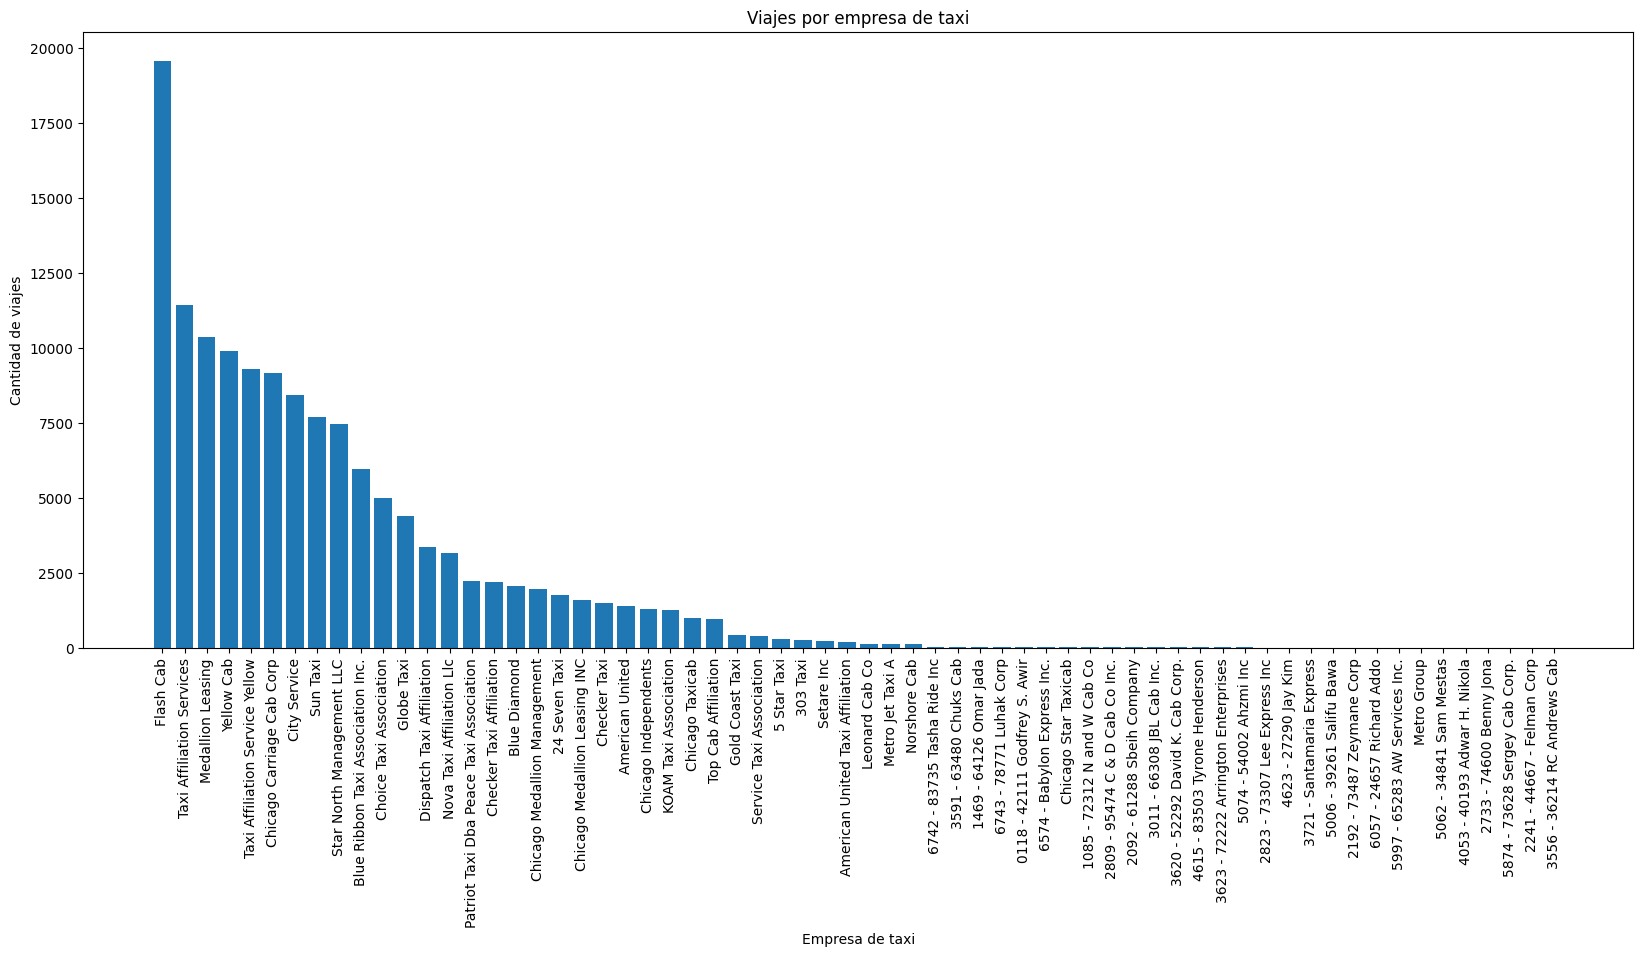

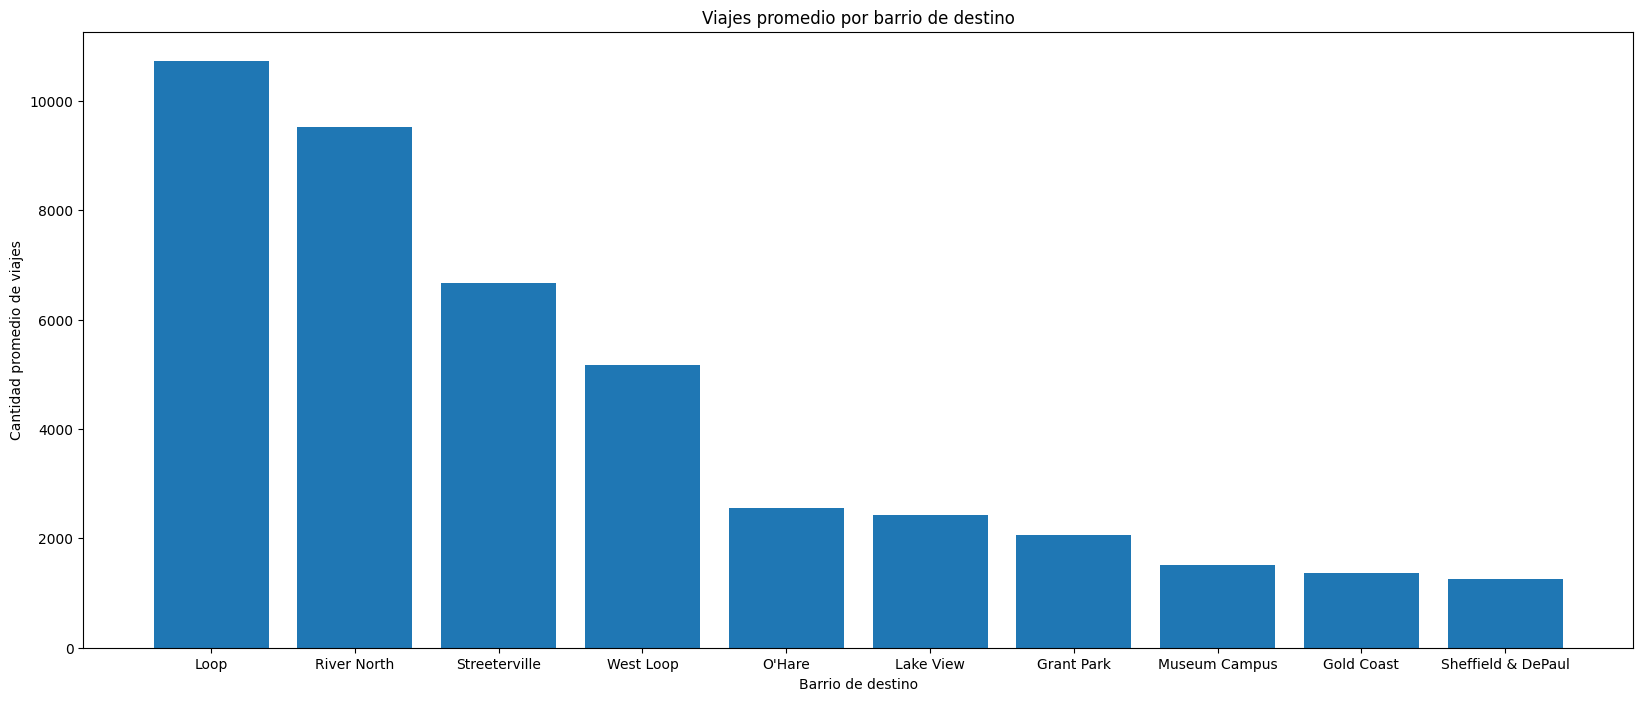

In [4]:
#Gráficos
#Empresas de taxis:
plt.figure(figsize = (20, 8))
plt.bar(df_trips['company_name'], df_trips['trips_amount'])
plt.title('Viajes por empresa de taxi')
plt.xlabel('Empresa de taxi')
plt.ylabel('Cantidad de viajes')
plt.xticks(rotation = 90)
plt.show()

#Barrio de destino:
plt.figure(figsize = (20, 8))
plt.bar(df_dropoff_sorted_10['dropoff_location_name'], df_dropoff_sorted_10['average_trips'])
plt.title('Viajes promedio por barrio de destino')
plt.xlabel('Barrio de destino')
plt.ylabel('Cantidad promedio de viajes')
plt.show()

# Observaciones finales del análisis exploratorio:
Se ha realizado una revisión a las tablas de cantidad de viajes por empresa de taxis y los viajes promedio por barrio de destino.
Se encuentra que a pesar de tener 94 empresas de taxis, la empresa Flash Cab domina ampliamente el mercado respecto a las otras empresas. Adicionalmente se tienen unas 8 empresas que realizan 7500 viajes o mas, y ya el mercado se reparte entre las otras 85 empresas.
Del mismo modo, se encontraron los 10 principales barrios de destino de estos viajes, siendo los barrios Loop, River North, Streeterville y West loop los que predominan en los destinos deseados.

# Prueba de hipótesis

In [5]:
#Cargar archivo
df_airport = pd.read_csv('/datasets/project_sql_result_07.csv')

#Revisión inicial
print(df_airport.info())
print(df_airport.head())
print(df_airport.duplicated().sum())

#Eliminar duplicados:
df_airport = df_airport.drop_duplicates().reset_index(drop = True)
print()
print(df_airport.info())
print(df_airport.duplicated().sum())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1068 entries, 0 to 1067
Data columns (total 3 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   start_ts            1068 non-null   object 
 1   weather_conditions  1068 non-null   object 
 2   duration_seconds    1068 non-null   float64
dtypes: float64(1), object(2)
memory usage: 25.2+ KB
None
              start_ts weather_conditions  duration_seconds
0  2017-11-25 16:00:00               Good            2410.0
1  2017-11-25 14:00:00               Good            1920.0
2  2017-11-25 12:00:00               Good            1543.0
3  2017-11-04 10:00:00               Good            2512.0
4  2017-11-11 07:00:00               Good            1440.0
197

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 871 entries, 0 to 870
Data columns (total 3 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   start_ts           

## Observaciones:
Se carga el archivo .csv de la filtración ya realizada previamente, se realiza una revisión corta y se encuentran 197 filas duplicadas. Teniendo en cuenta que:
1. Es posible pero poco probable que en 197 ocasiones haya existido un servicio con mismo origen y destino a la misma hora y con la misma duración.
2. La presencia de estos datos podrían ensuciar el análisis a realizar.

Por lo anterior, se decide eliminar estos resultados duplicados y trabajar solo conlos 871 resultados singulares que permitirán hacer un análisis robusto.

## Análisis estadístico:
H0: No hay diferencia en la duración media de los viajes entre Loop y O'Hare entre los sábados lluviosos y los otros días

H1: Hay diferencia en la duración media de los viajes entre los sábados lluviosos y los otros días para el trayecto entre Loop y O´Hare


<class 'pandas.core.frame.DataFrame'>
Int64Index: 148 entries, 6 to 870
Data columns (total 4 columns):
 #   Column              Non-Null Count  Dtype         
---  ------              --------------  -----         
 0   start_ts            148 non-null    datetime64[ns]
 1   weather_conditions  148 non-null    object        
 2   duration_seconds    148 non-null    float64       
 3   dow                 148 non-null    int64         
dtypes: datetime64[ns](1), float64(1), int64(1), object(1)
memory usage: 5.8+ KB
None
<class 'pandas.core.frame.DataFrame'>
Int64Index: 723 entries, 0 to 869
Data columns (total 4 columns):
 #   Column              Non-Null Count  Dtype         
---  ------              --------------  -----         
 0   start_ts            723 non-null    datetime64[ns]
 1   weather_conditions  723 non-null    object        
 2   duration_seconds    723 non-null    float64       
 3   dow                 723 non-null    int64         
dtypes: datetime64[ns](1), float64

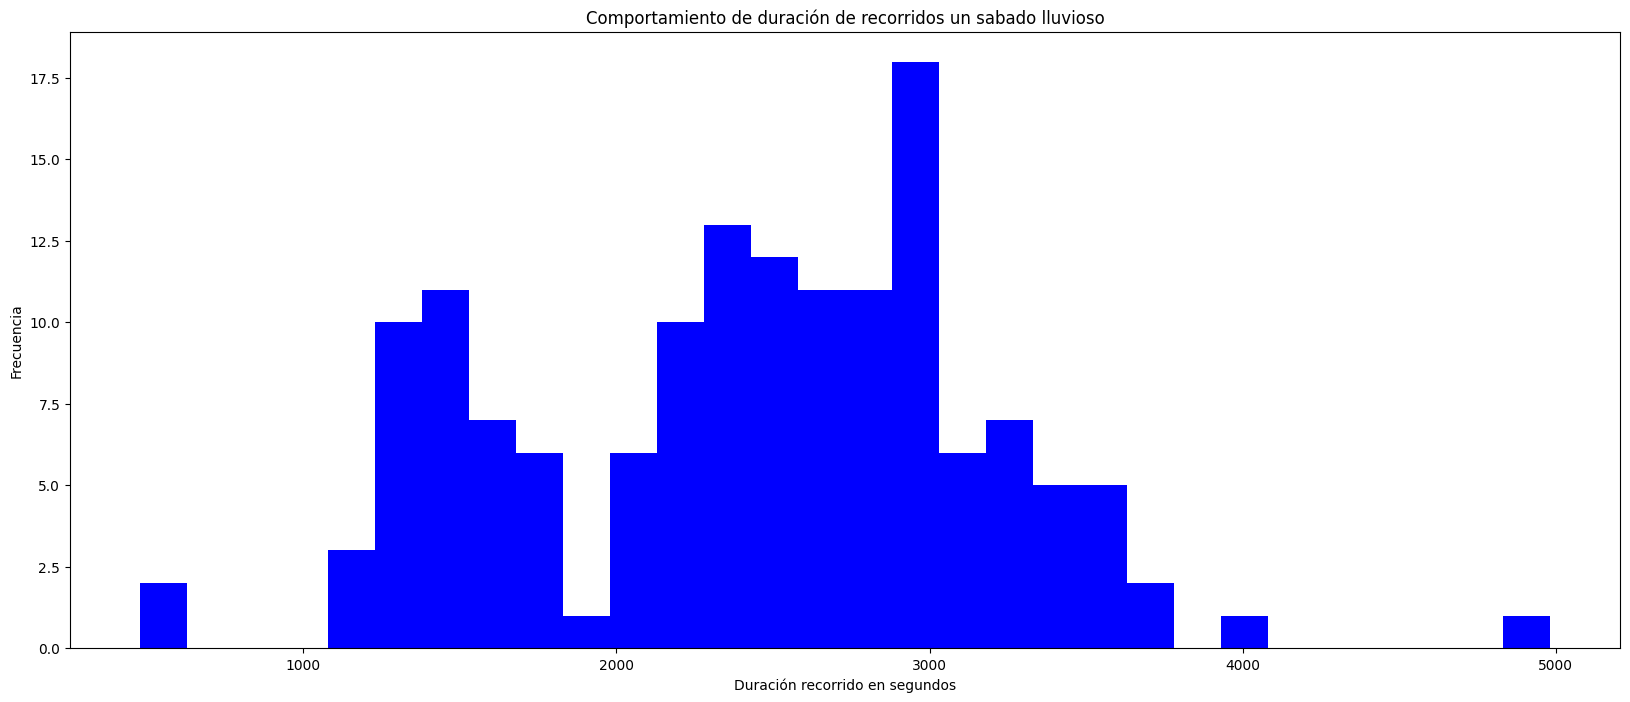

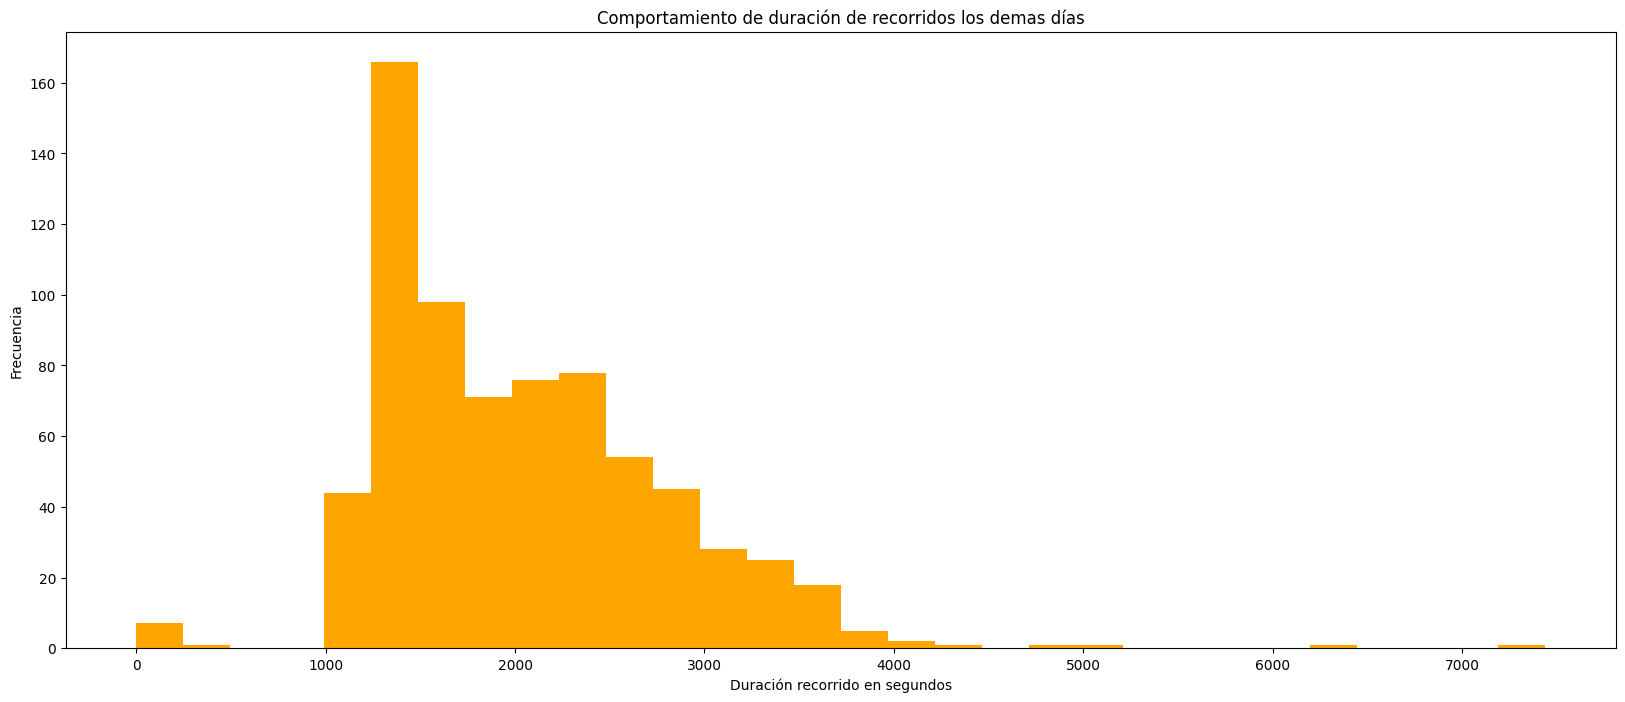

In [6]:
#Conversión de la columna start_ts a formato de fecha:
df_airport['start_ts'] = pd.to_datetime(df_airport['start_ts'])

#Adición de columna dow (day of week):
df_airport['dow'] = df_airport['start_ts'].dt.dayofweek

#Creación de tabla con viajes los sabados lluviosos
df_airport_sat_bad = df_airport[(df_airport['dow'] == 5) & (df_airport['weather_conditions'] == 'Bad')]
print(df_airport_sat_bad.info())

#Creación del grupo "otros dias"
df_airport_others = df_airport[~((df_airport['dow'] == 5) & (df_airport['weather_conditions'] == 'Bad'))]
print(df_airport_others.info())

#VERIFICADO - Verificación que se haya hecho buena segregación
#if len(df_airport_sat_bad) + len(df_airport_others) == len(df_airport):
#    print('buena segregación')
#else:
#    print('revise el código')

#Creación histogramas:
#sábado lluvioso
plt.figure(figsize = (20, 8))
plt.hist(df_airport_sat_bad['duration_seconds'], bins=30, color='blue')
plt.title('Comportamiento de duración de recorridos un sabado lluvioso')
plt.xlabel('Duración recorrido en segundos')
plt.ylabel('Frecuencia')
plt.show()

#otros días
plt.figure(figsize = (20, 8))
plt.hist(df_airport_others['duration_seconds'], bins=30, color='orange')
plt.title('Comportamiento de duración de recorridos los demas días')
plt.xlabel('Duración recorrido en segundos')
plt.ylabel('Frecuencia')
plt.show()
        


## Observaciones:
Se ha realizado un alistamiento del archivo CSV para poder comprobar la hipótesis deseada. El protocolo fue básicamente:
1. Cambiar la columna 'start_ts' a formato de fecha.
2. Generar una nueva columna para determinar el dia de la semana.
3. generar una segregación por día sábado y con condiciones de clima malas
4. generar una segregación por los días restantes.
5. Corroborar que se hiciera una buena segregación.
6. Generar histogramas para evaluar el comportamiento de la duración de los viajes.

Luego de esta revisión se ha encontrado que ambas segregaciones realizadas, es decir, la duración usual de los viajes, siguen una distribución normal. Esto nos permite definir que para corroborar la validez de la hipótesis planteemos una prueba t.

Dado que se tienen buenos datos, propongo una significancia del 5%.

In [7]:
#Prueba estadística t:

alpha = 0.05  # Nivel de significancia 
results = st.ttest_ind(df_airport_sat_bad['duration_seconds'], df_airport_others['duration_seconds'], equal_var=False)

print(f'Valor p: {results.pvalue}')
if results.pvalue < alpha:
    print("Rechazamos la hipótesis nula - Hay diferencia entre las duraciones medias de los viajes")
else:
    print("No podemos rechazar la hipótesis nula - La diferencia media de los viajes no es significativa")

# Calcula las medias para interpretar la dirección de la diferencia
print(f"Duración media de viajes un sábado lluvioso: {df_airport_sat_bad['duration_seconds'].mean():.2f} segundos")
print(f"Duración media de viajes los otros días: {df_airport_others['duration_seconds'].mean():.2f} segundos")

Valor p: 9.126383933880083e-08
Rechazamos la hipótesis nula - Hay diferencia entre las duraciones medias de los viajes
Duración media de viajes un sábado lluvioso: 2409.23 segundos
Duración media de viajes los otros días: 2032.25 segundos


# Conclusiones generales:
Se realiza el proyecto del Sprint 8, como analista de la empresa de viajes compartidos "Zuber".

Evaluamos patrones de comportamiento de los viajes y encontramos algunas preferencias de los clientes como:
1. Uso de la empresa Flash Cab para realizar sus viajes con mas de 18.000 recorridos.
2. El destino preferido de los trayectos fue hacia los barrios Loop, River North, Streeterville y West Loop, los cuales tienen entre 5000 y 10000 servicios realizados.

Adicional a ello, encontramos que efectos externos como día de la semana y estado metereológico afectan la duración de los viajes, eso aplicado especificante a trayectos realizados los sábados con lluvia entre los sectores de Loop y O´Hare se observa una diferencia mayor a los 5 minutos entre las comparaciones

Estos resultados les permitirán al equipo de planificación establecer campañas en determinados puntos de la ciudad, y al equipo de mercadeo realizar análisis más profundos para formular mejores estrategias de servicio.